<a href="https://colab.research.google.com/github/iyoob-utexas/ds4e/blob/main/notebooks/n8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

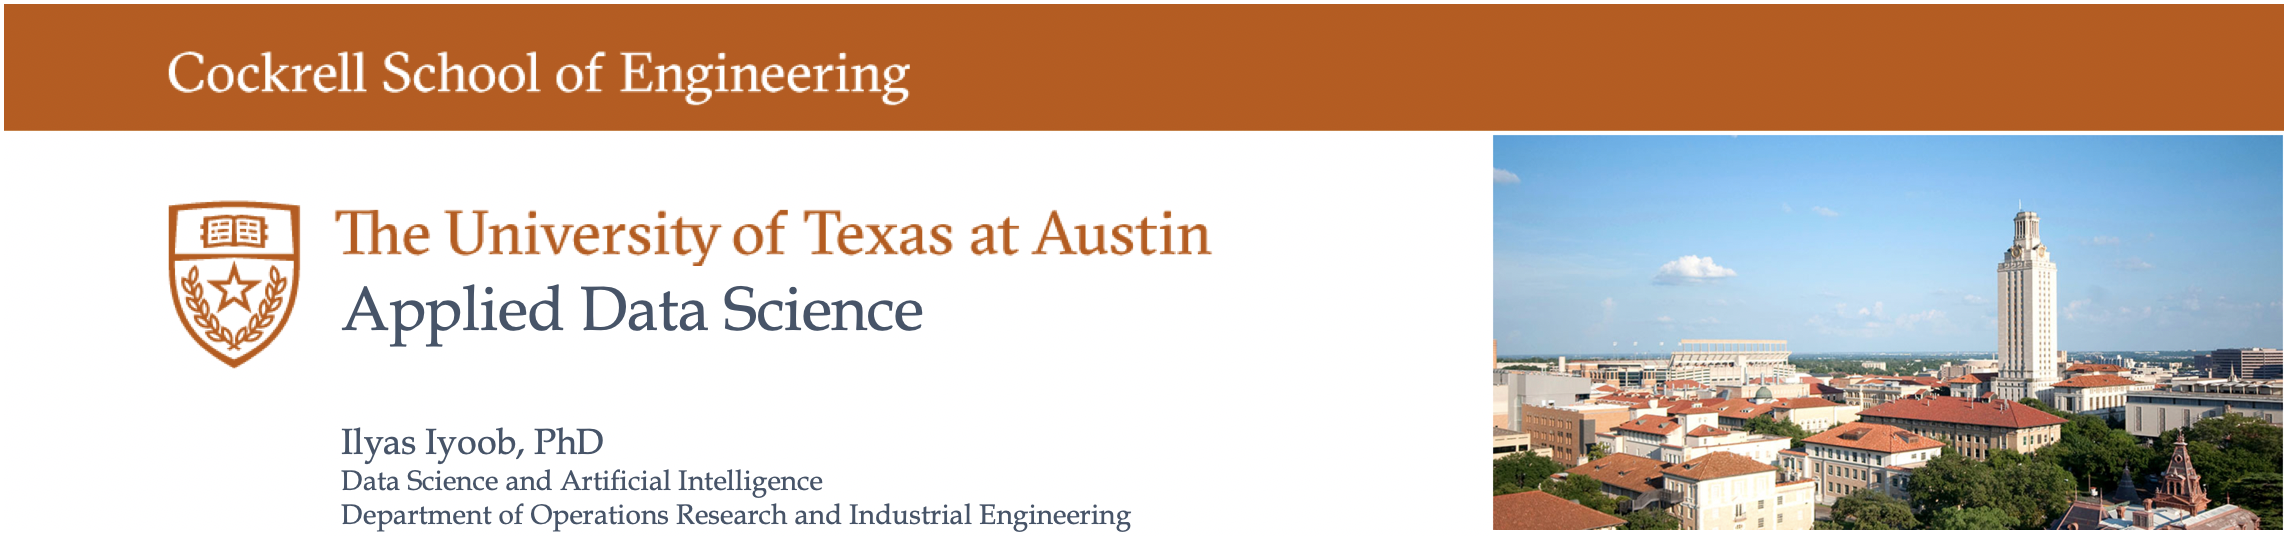

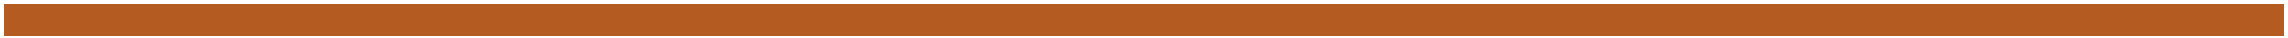

## <font color='#475468'> Preference Recommendations:</font>
### <font color='#475468'> Can you recommend movies that users may like?</font>

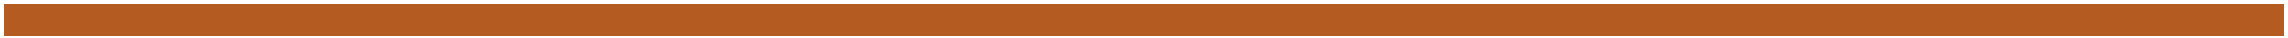

## Initialize

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Load Data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Movie metadata
dfMvs = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/data/ds4e/movies/movies_metadata_clean.csv')

# User ratings for each movie
dfMvsRtg = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/data/ds4e/movies/movies_ratings_small.csv')

## Build Recommendations

WHITEBOARD >>

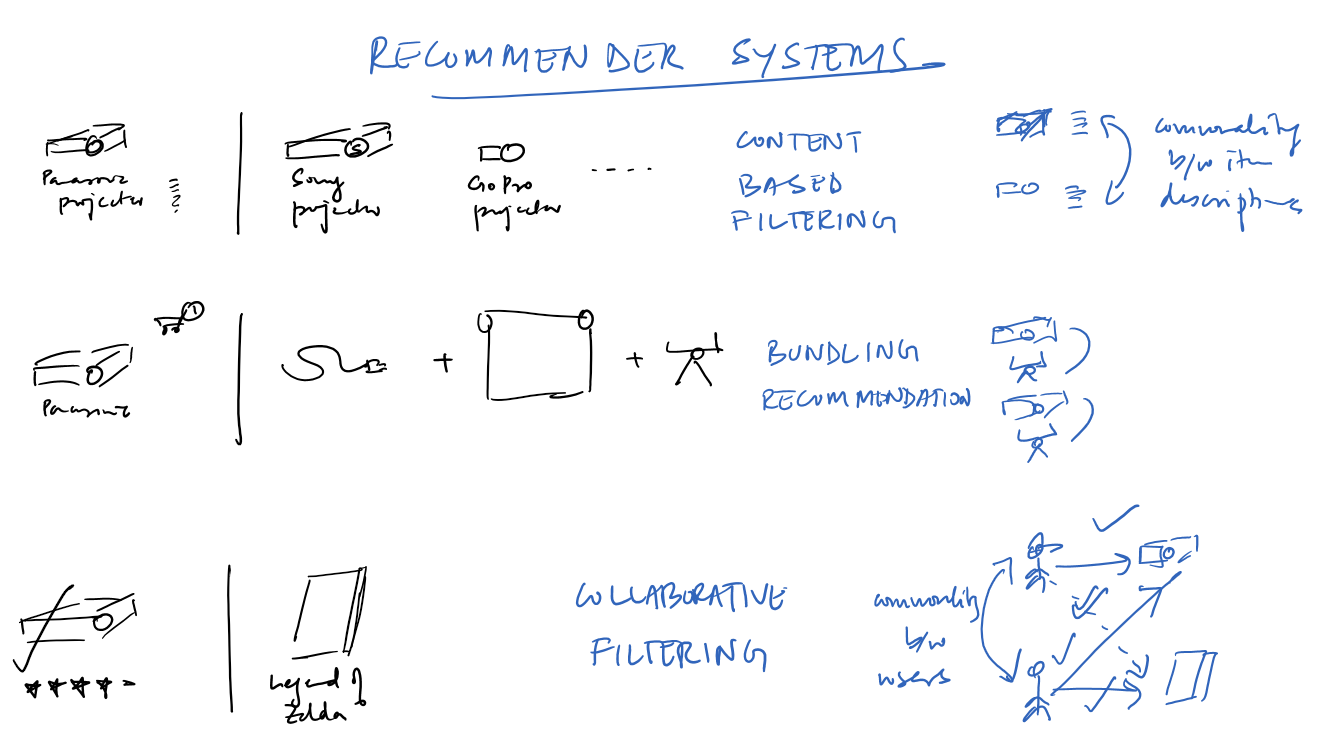

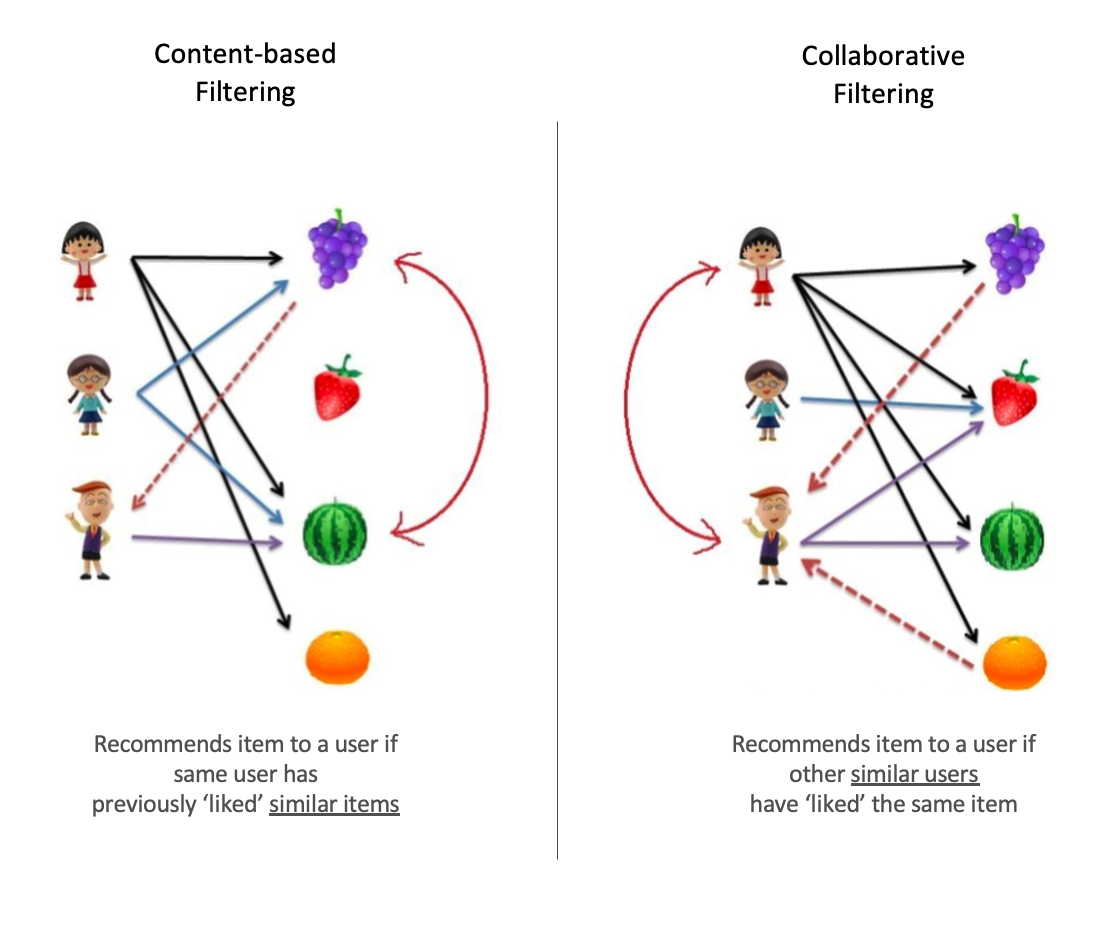

<< WHITEBOARD

Let us first try to build a recommender using movie content such as descriptions and taglines, also known as **Content Based Filtering**

### 1. Content Based Filtering

The idea here is to determine how similar the descriptions are based on the terms used in the descriptions - while ignoring commonly used words.  Then recommend other items with similar descriptions.  In order to do this, **TF-IDF Vectorization** is used.

WHITEBOARD >>

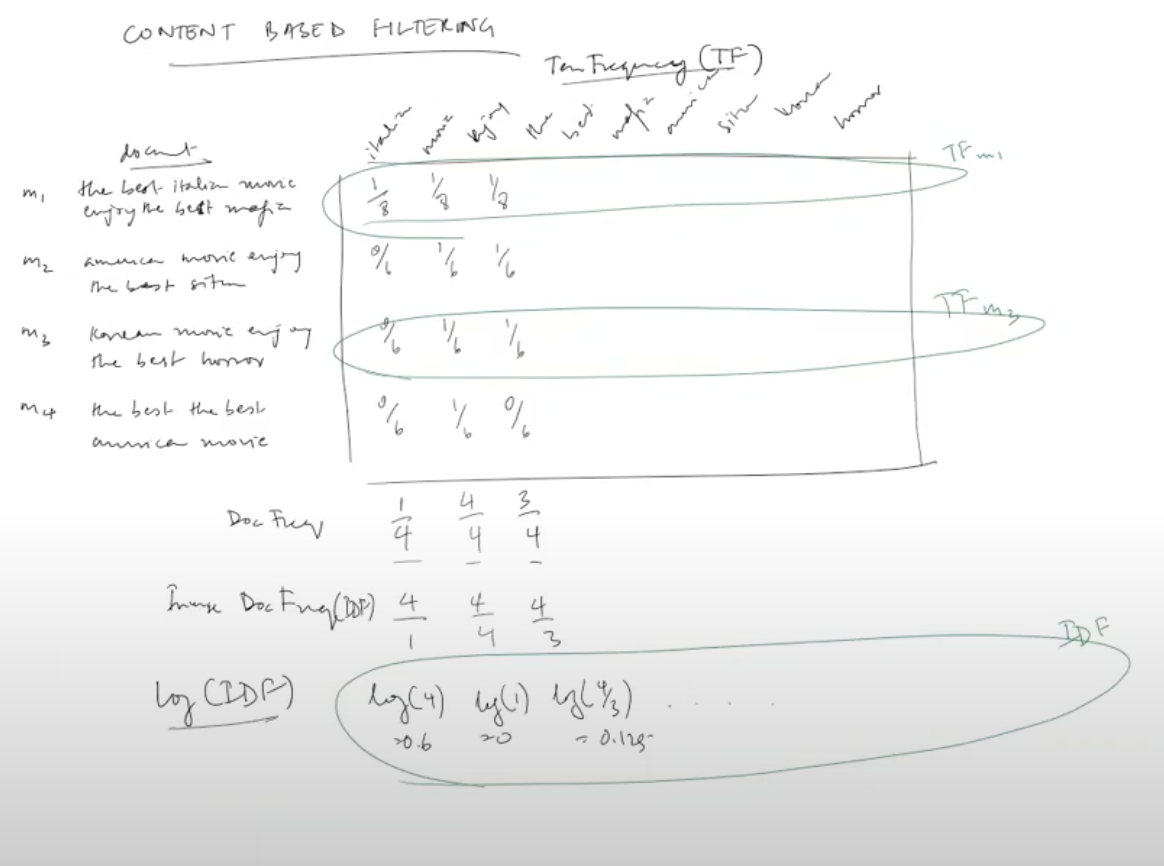

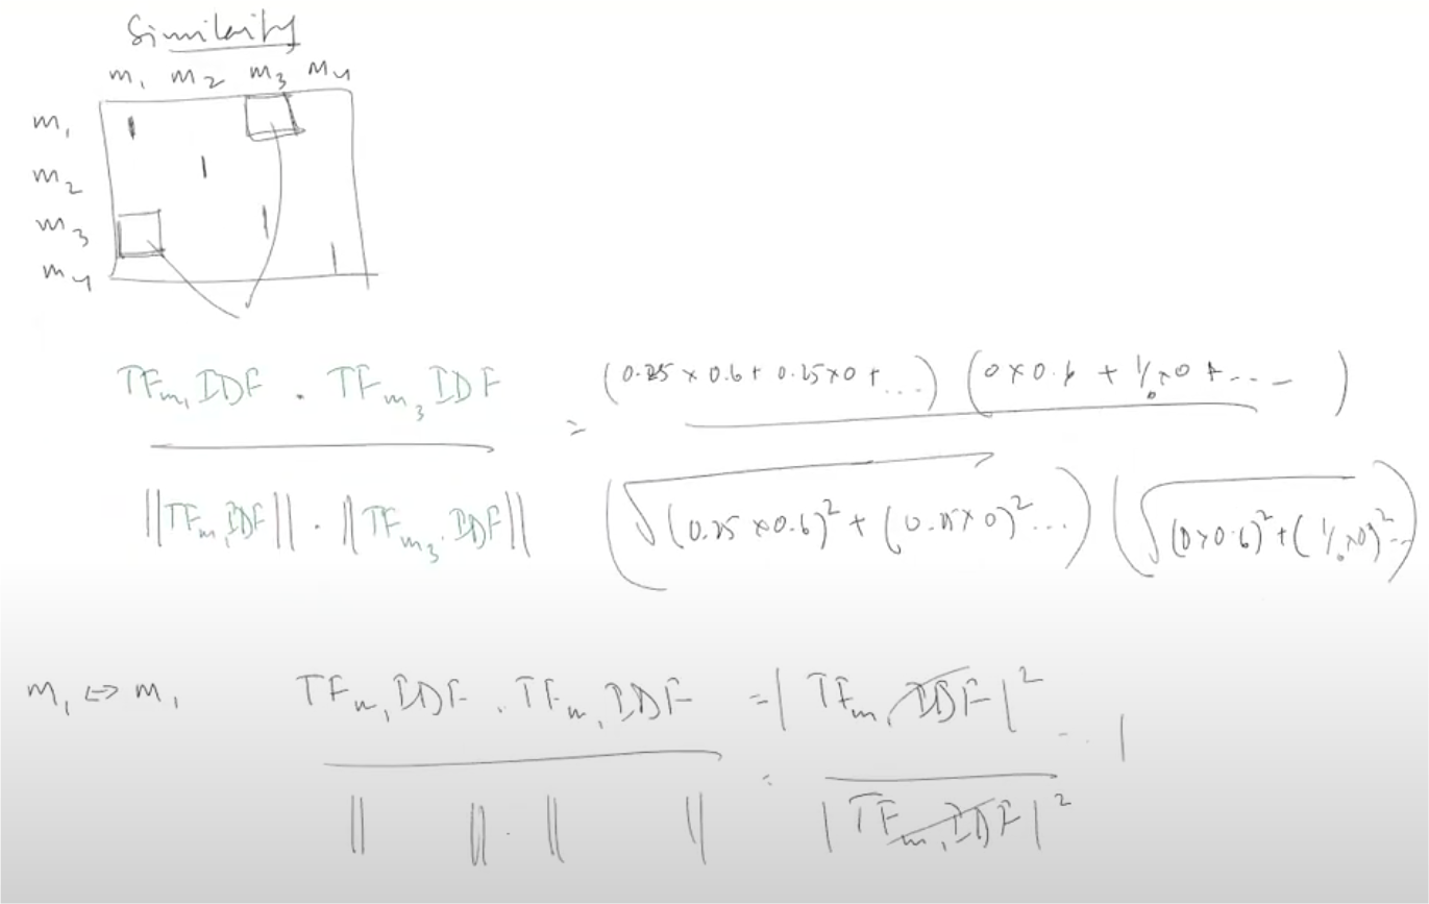

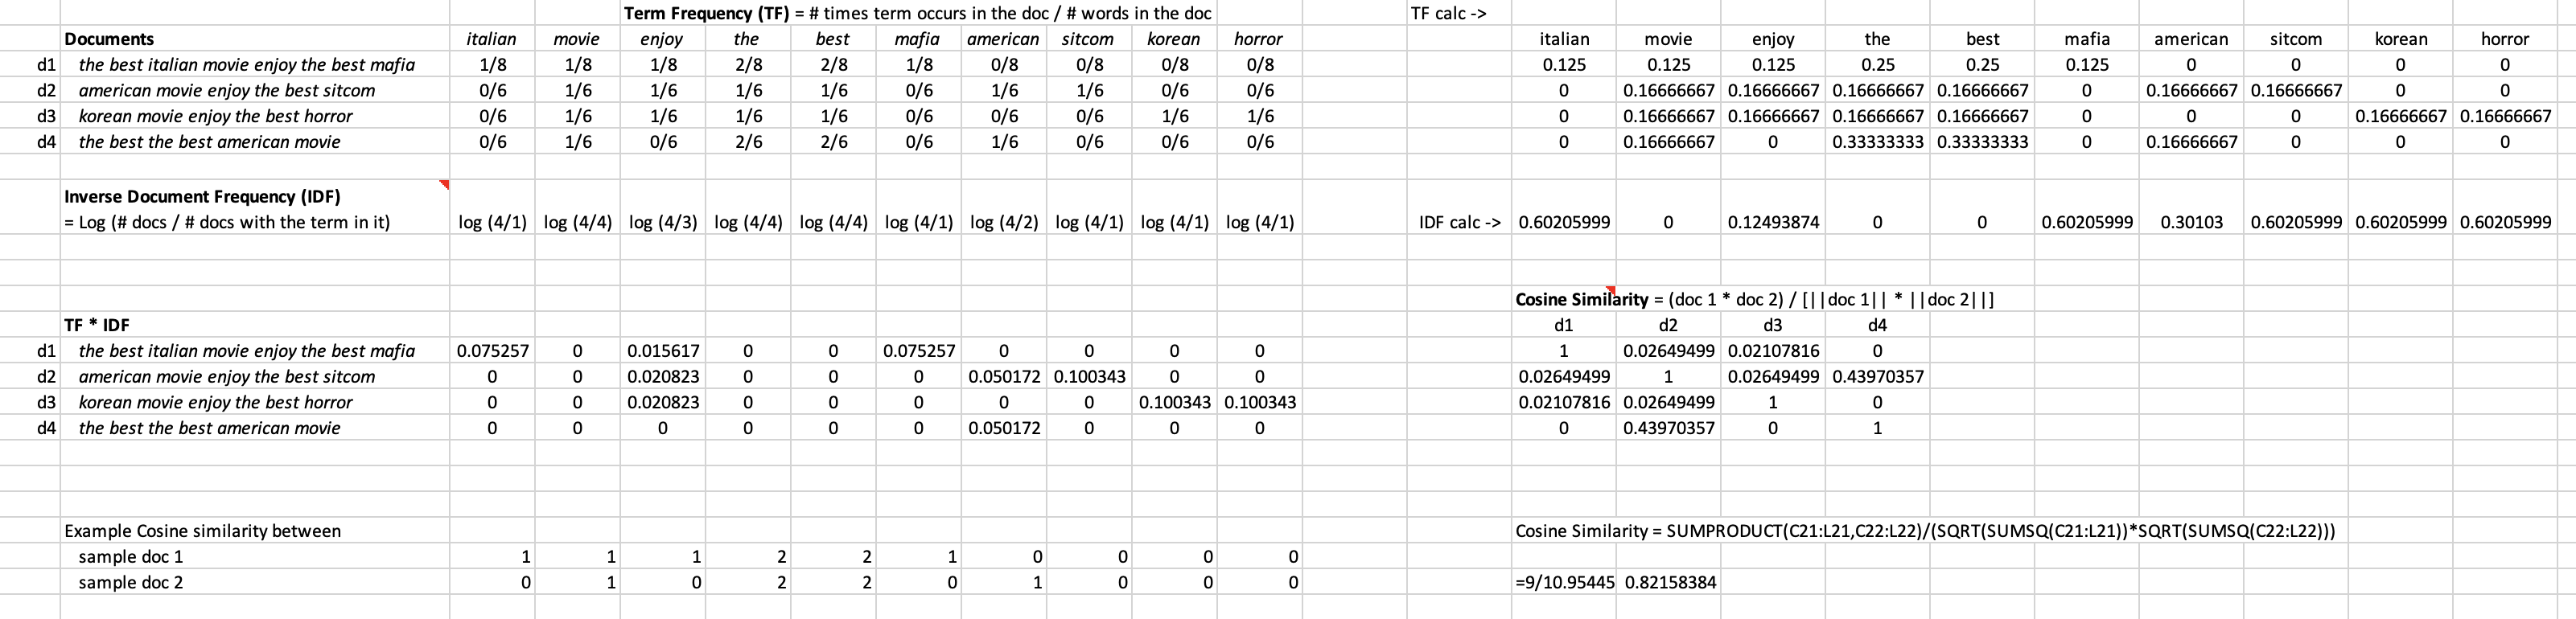

<< WHITEBOARD

#### Prepare data

In [4]:
dfMvs.head()

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,10/30/1995,373554033,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,12/15/1995,262797249,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,12/22/1995,0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,12/22/1995,81452156,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,2/10/1995,76578911,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173


In [5]:
dfMvs.shape

(45463, 24)

In [6]:
# Remove duplicates
dfMvs.drop_duplicates(subset ='title', keep = 'last', inplace = True)
dfMvs.shape

(42277, 24)

In [7]:
# Prepare the description column

dfMvs['description'] = dfMvs['title'] + ' ' + dfMvs['tagline'] + ' ' + dfMvs['overview']
dfMvs['description'] = dfMvs['description'].fillna('')

#### Build Model

In [8]:
# Generate a matrix of common terms that show up in each movie

from sklearn.feature_extraction.text import TfidfVectorizer
mdlTfvMvs = TfidfVectorizer(stop_words='english')
tfidf_matrix = mdlTfvMvs.fit_transform(dfMvs['description'])
tfidf_matrix.shape

(42277, 47936)

The similarity between any two movies (x) and (y) is defined as the **Cosine Similarity**:
cosine(x,y)=x.y⊺||x||.||y||

Since we have used the TF-IDF Vectorizer, calculating the Dot Product will directly give us the Cosine Similarity Score.

In [9]:
# Calculate cosine similarity between each pair of movies as a function of the similarity of the common terms

from sklearn.metrics.pairwise import cosine_similarity
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)
cosine_sim.shape

(42277, 42277)

#### Predict

In [10]:
# Prepare recommendation function (build code from scratch and then package as function for ease of understanding)

titles = dfMvs['title']
indices = pd.Series(dfMvs.index, index=dfMvs['title'])

def get_recommendations(title):
    idx = indices[title]
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:10]
    movie_indices = [i[0] for i in sim_scores]
    return titles[movie_indices]

In [11]:
get_recommendations('The Dark Knight Rises')

,title
238,Farinelli
18,Ace Ventura: When Nature Calls
20962,New York: A Documentary Film
5326,The Powerpuff Girls Movie
42201,The Booth
27692,Bert: The Last Virgin
30680,Blank: A Vinylmation Love Story
26952,The Family Way
25977,Van Wilder: Freshman Year


In [12]:
get_recommendations('Sudden Death')

,title
21618,Short Term 12
15073,Angel of Death
7398,Forever Fever
8597,Operation Crossbow
16826,Cave of Forgotten Dreams
16685,Lloyd's of London
272,Milk Money
399,Brother Minister: The Assassination of Malcolm X
37288,Too Fat Too Furious


These recommendations suggest movies that are close in name and description. Anyone querying our engine for recommendations based on a movie will receive the same recommendations for that movie, regardless of who s/he is.  This is a good way of providing recommendations especially when no further data is available.  

What if we also have data on personal tastes?  Can we make recommendations that capture these tastes and recommend movies that are more personalized?  For this, we use a technique called **Collaborative Filtering** which is based on the idea that users similar to me can be used to predict how much I will like a particular product or service those users have used/experienced but I have not.

utexas_ds_orie_divider_gray.png

### 2. Collaborative Filtering

The idea here is that a user x movie matrix is decomposed into a product of user x concept . concept x concept . concept x movie matrices.  These can then be used to derive similarities between users.  This process is known as **Singular Value Decomposition**.

WHITEBOARD >>

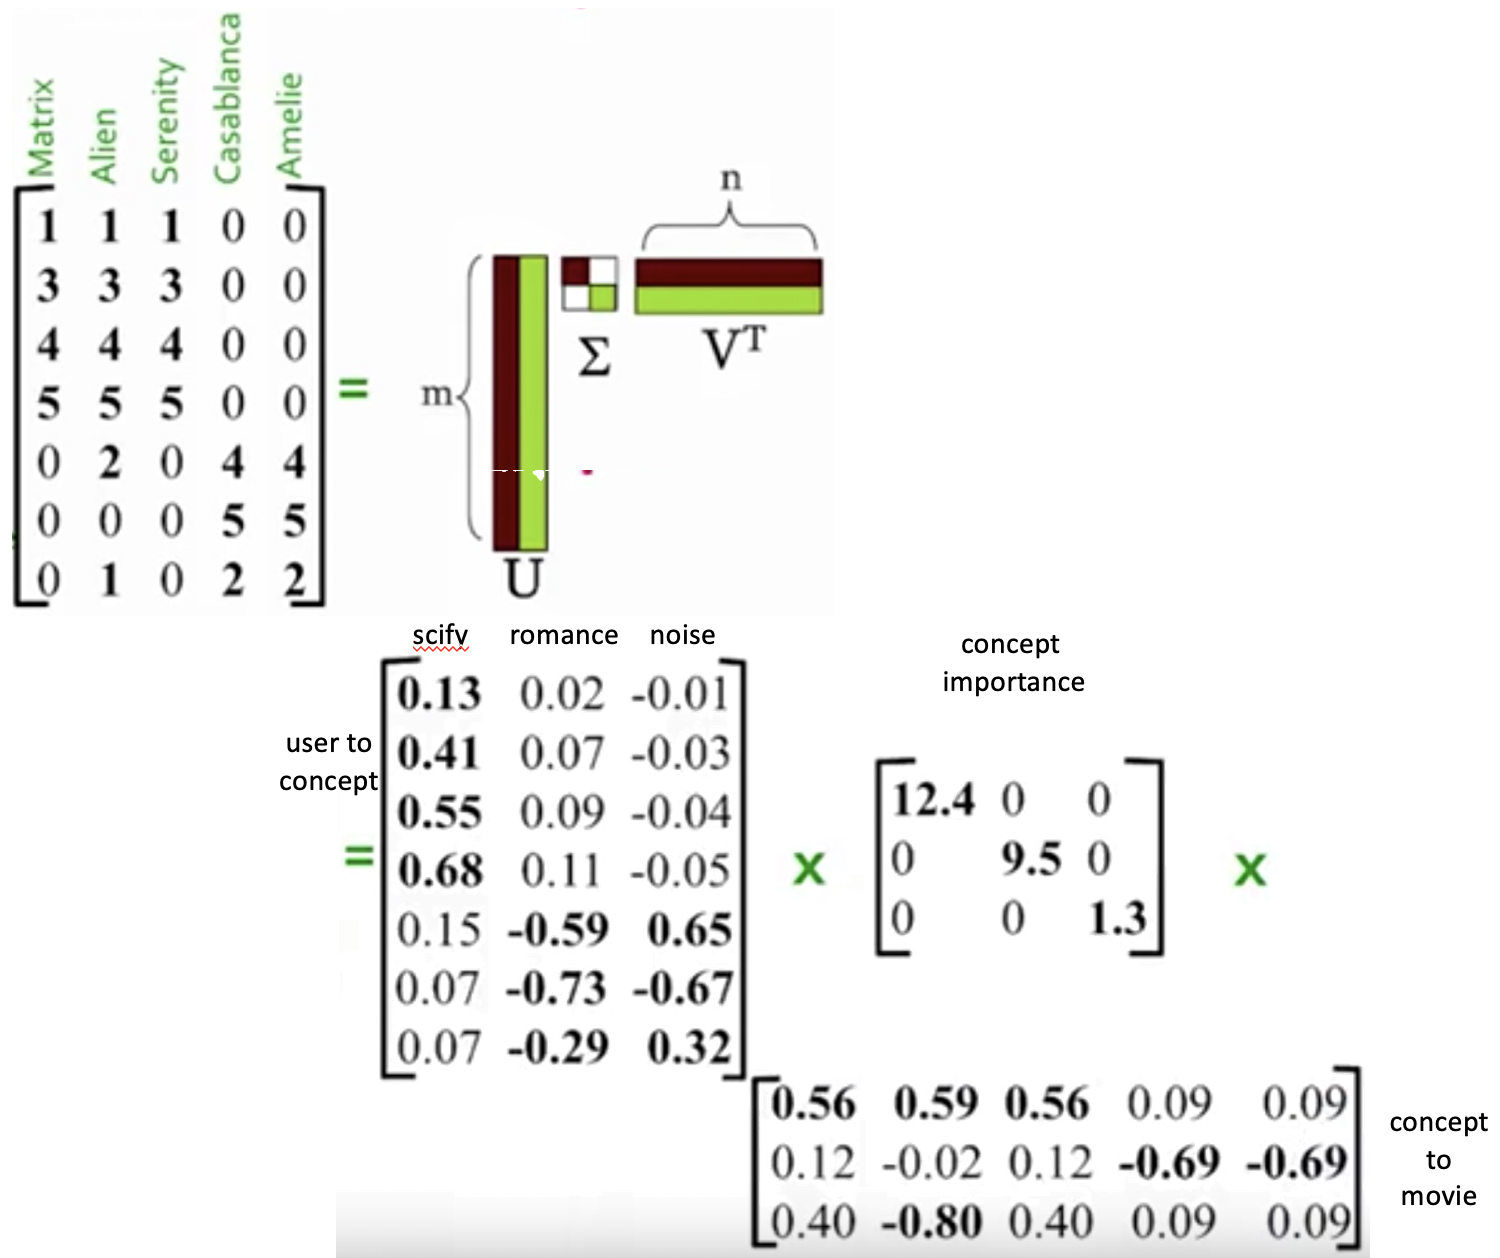

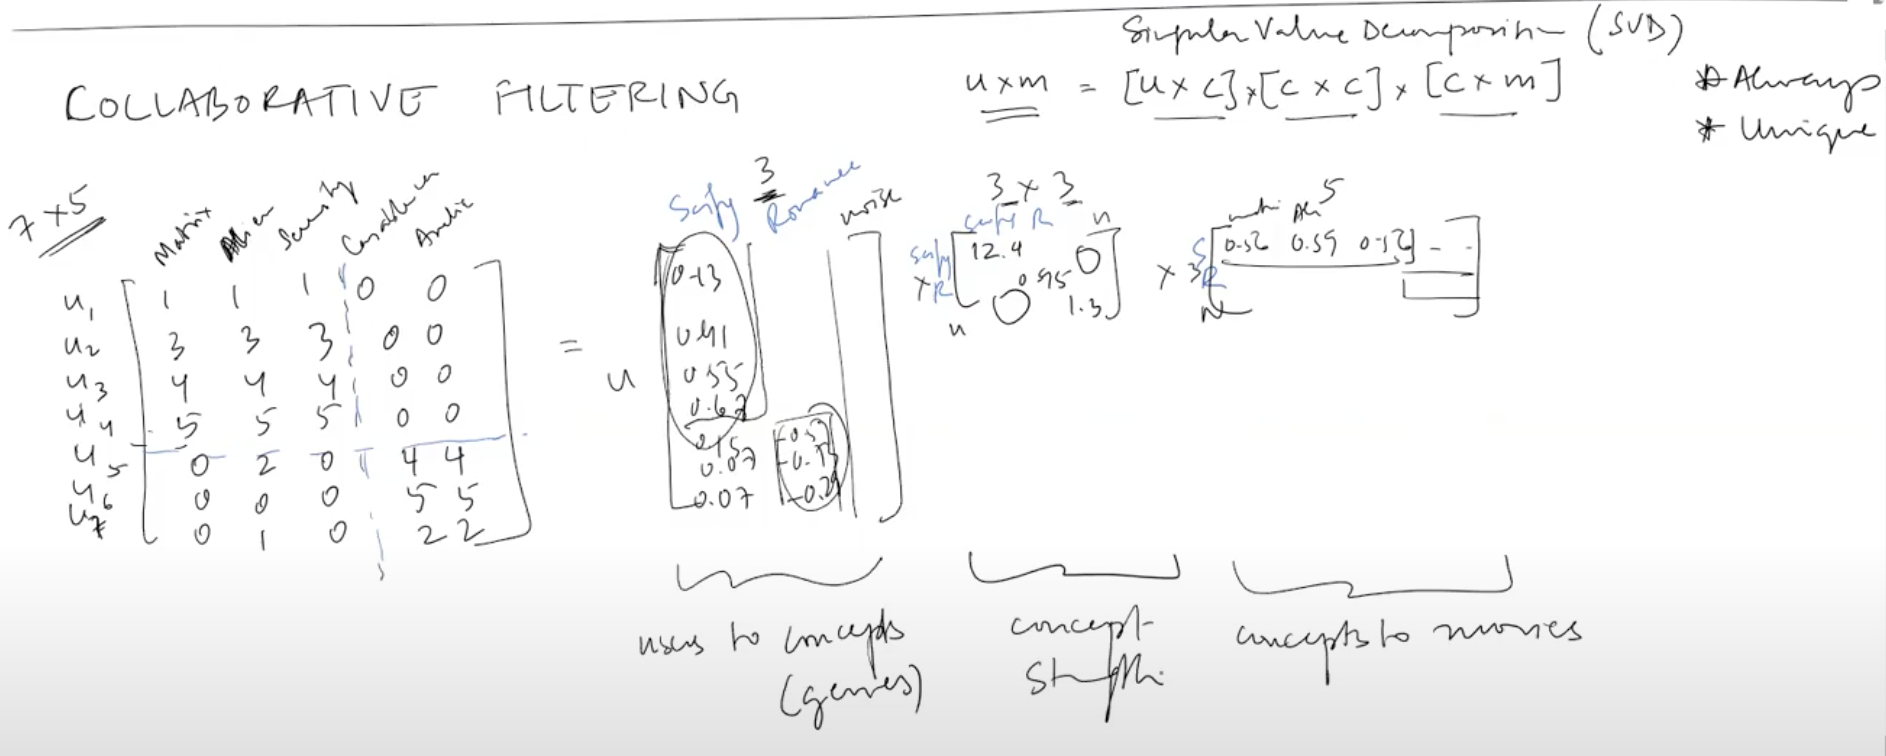

<< WHITEBOARD

#### Prepare data

In [13]:
dfMvsRtg.head(10)

,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182
3,1,1129,2.0,1260759185
4,1,1172,4.0,1260759205
5,1,1263,2.0,1260759151
6,1,1287,2.0,1260759187
7,1,1293,2.0,1260759148
8,1,1339,3.5,1260759125
9,1,1343,2.0,1260759131


#### Build Model

In [27]:
!pip3 install scikit-surprise #or !conda install -c conda-forge scikit-surprise
!pip install "numpy<2" #since latest surprise not compatible with latest numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 30.0 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python-headless 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
tobler 0.13.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
rasterio 1.5.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.1

In [14]:
# Prepare data into Surprise library format


from surprise import Dataset
from surprise import Reader
from surprise.model_selection import train_test_split

reader = Reader(rating_scale=(0,5))
X = Dataset.load_from_df(dfMvsRtg[['userId', 'movieId', 'rating']], reader)
X_train, X_test = train_test_split(X, test_size=.25)

In [15]:
# Define SVD model

from surprise import SVD

mdlSvdMvsRtg = SVD()

In [16]:
# Fit SVD model

mdlSvdMvsRtg.fit(X_train)
test_pred = mdlSvdMvsRtg.test(X_test)

In [17]:
# Evalute SVD accuracy

from surprise import accuracy

accuracy.rmse(test_pred)

RMSE: 0.9028


0.9028214197881161

In [18]:
# Tune hyperparameters

from surprise.model_selection import GridSearchCV

param_grid = {'n_epochs': [5, 10, 15], 'lr_all': [0.002, 0.005],
              'reg_all': [0.4, 0.6]}
gs = GridSearchCV(SVD, param_grid, measures=['rmse', 'mae'], cv=3)

gs.fit(X)

# best RMSE score
print(gs.best_score['rmse'])

# combination of parameters that gave the best RMSE score
print(gs.best_params['rmse'])

0.9090837804803219
{'n_epochs': 15, 'lr_all': 0.005, 'reg_all': 0.4}


In [19]:
# Cross-validate

from surprise.model_selection import cross_validate

cross_validate(mdlSvdMvsRtg, X, measures=['RMSE', 'MAE'], cv=5, verbose=True)

Evaluating RMSE, MAE of algorithm SVD on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.9010  0.9001  0.8904  0.8966  0.9009  0.8978  0.0040  
MAE (testset)     0.6917  0.6962  0.6854  0.6900  0.6959  0.6918  0.0040  
Fit time          2.10    1.56    1.43    1.45    1.45    1.60    0.25    
Test time         0.32    0.14    0.26    0.12    0.14    0.20    0.08    


{'test_rmse': array([0.90104246, 0.90010477, 0.89043225, 0.89662665, 0.90091603]),
 'test_mae': array([0.69168479, 0.69618402, 0.68544475, 0.68998361, 0.69586075]),
 'fit_time': (2.100423812866211,
  1.5550236701965332,
  1.4318585395812988,
  1.4496355056762695,
  1.4540016651153564),
 'test_time': (0.3182861804962158,
  0.14070534706115723,
  0.26120495796203613,
  0.1198880672454834,
  0.13898992538452148)}

Let us now use the trained model to arrive at predictions.

#### Predict

Let's first see which movies user # 1 has already viewed.

In [20]:
dfMvsRtg[dfMvsRtg['userId'] == 1]

,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182
3,1,1129,2.0,1260759185
4,1,1172,4.0,1260759205
5,1,1263,2.0,1260759151
6,1,1287,2.0,1260759187
7,1,1293,2.0,1260759148
8,1,1339,3.5,1260759125
9,1,1343,2.0,1260759131


Now, let's predict what rating user # 1 would give to movie # 302 (since he/she hasn't seen it yet)

In [21]:
mdlSvdMvsRtg.predict(1, 302)

Prediction(uid=1, iid=302, r_ui=None, est=2.896045629845123, details={'was_impossible': False})

One startling feature of this recommender system is that it doesn't care what the movie is (or what it contains). It works purely on the basis of an assigned movie ID and tries to predict ratings based on how the other users have predicted the movie.

An extension to this could be to create a hybrid model that uses content filtering in the initial phase when user preferences are not available, and then gradually shift to a collaborative filtering model blended with some content filtering.

## Takeaways

* Introduced content-based filtering to recommend items based on their descriptions using *TF-IDF Vectorization*
* In the event that user preference data is available, collaborative filtering is leveraged to recommend items based on other similar users using *Singular Value Decomposition*

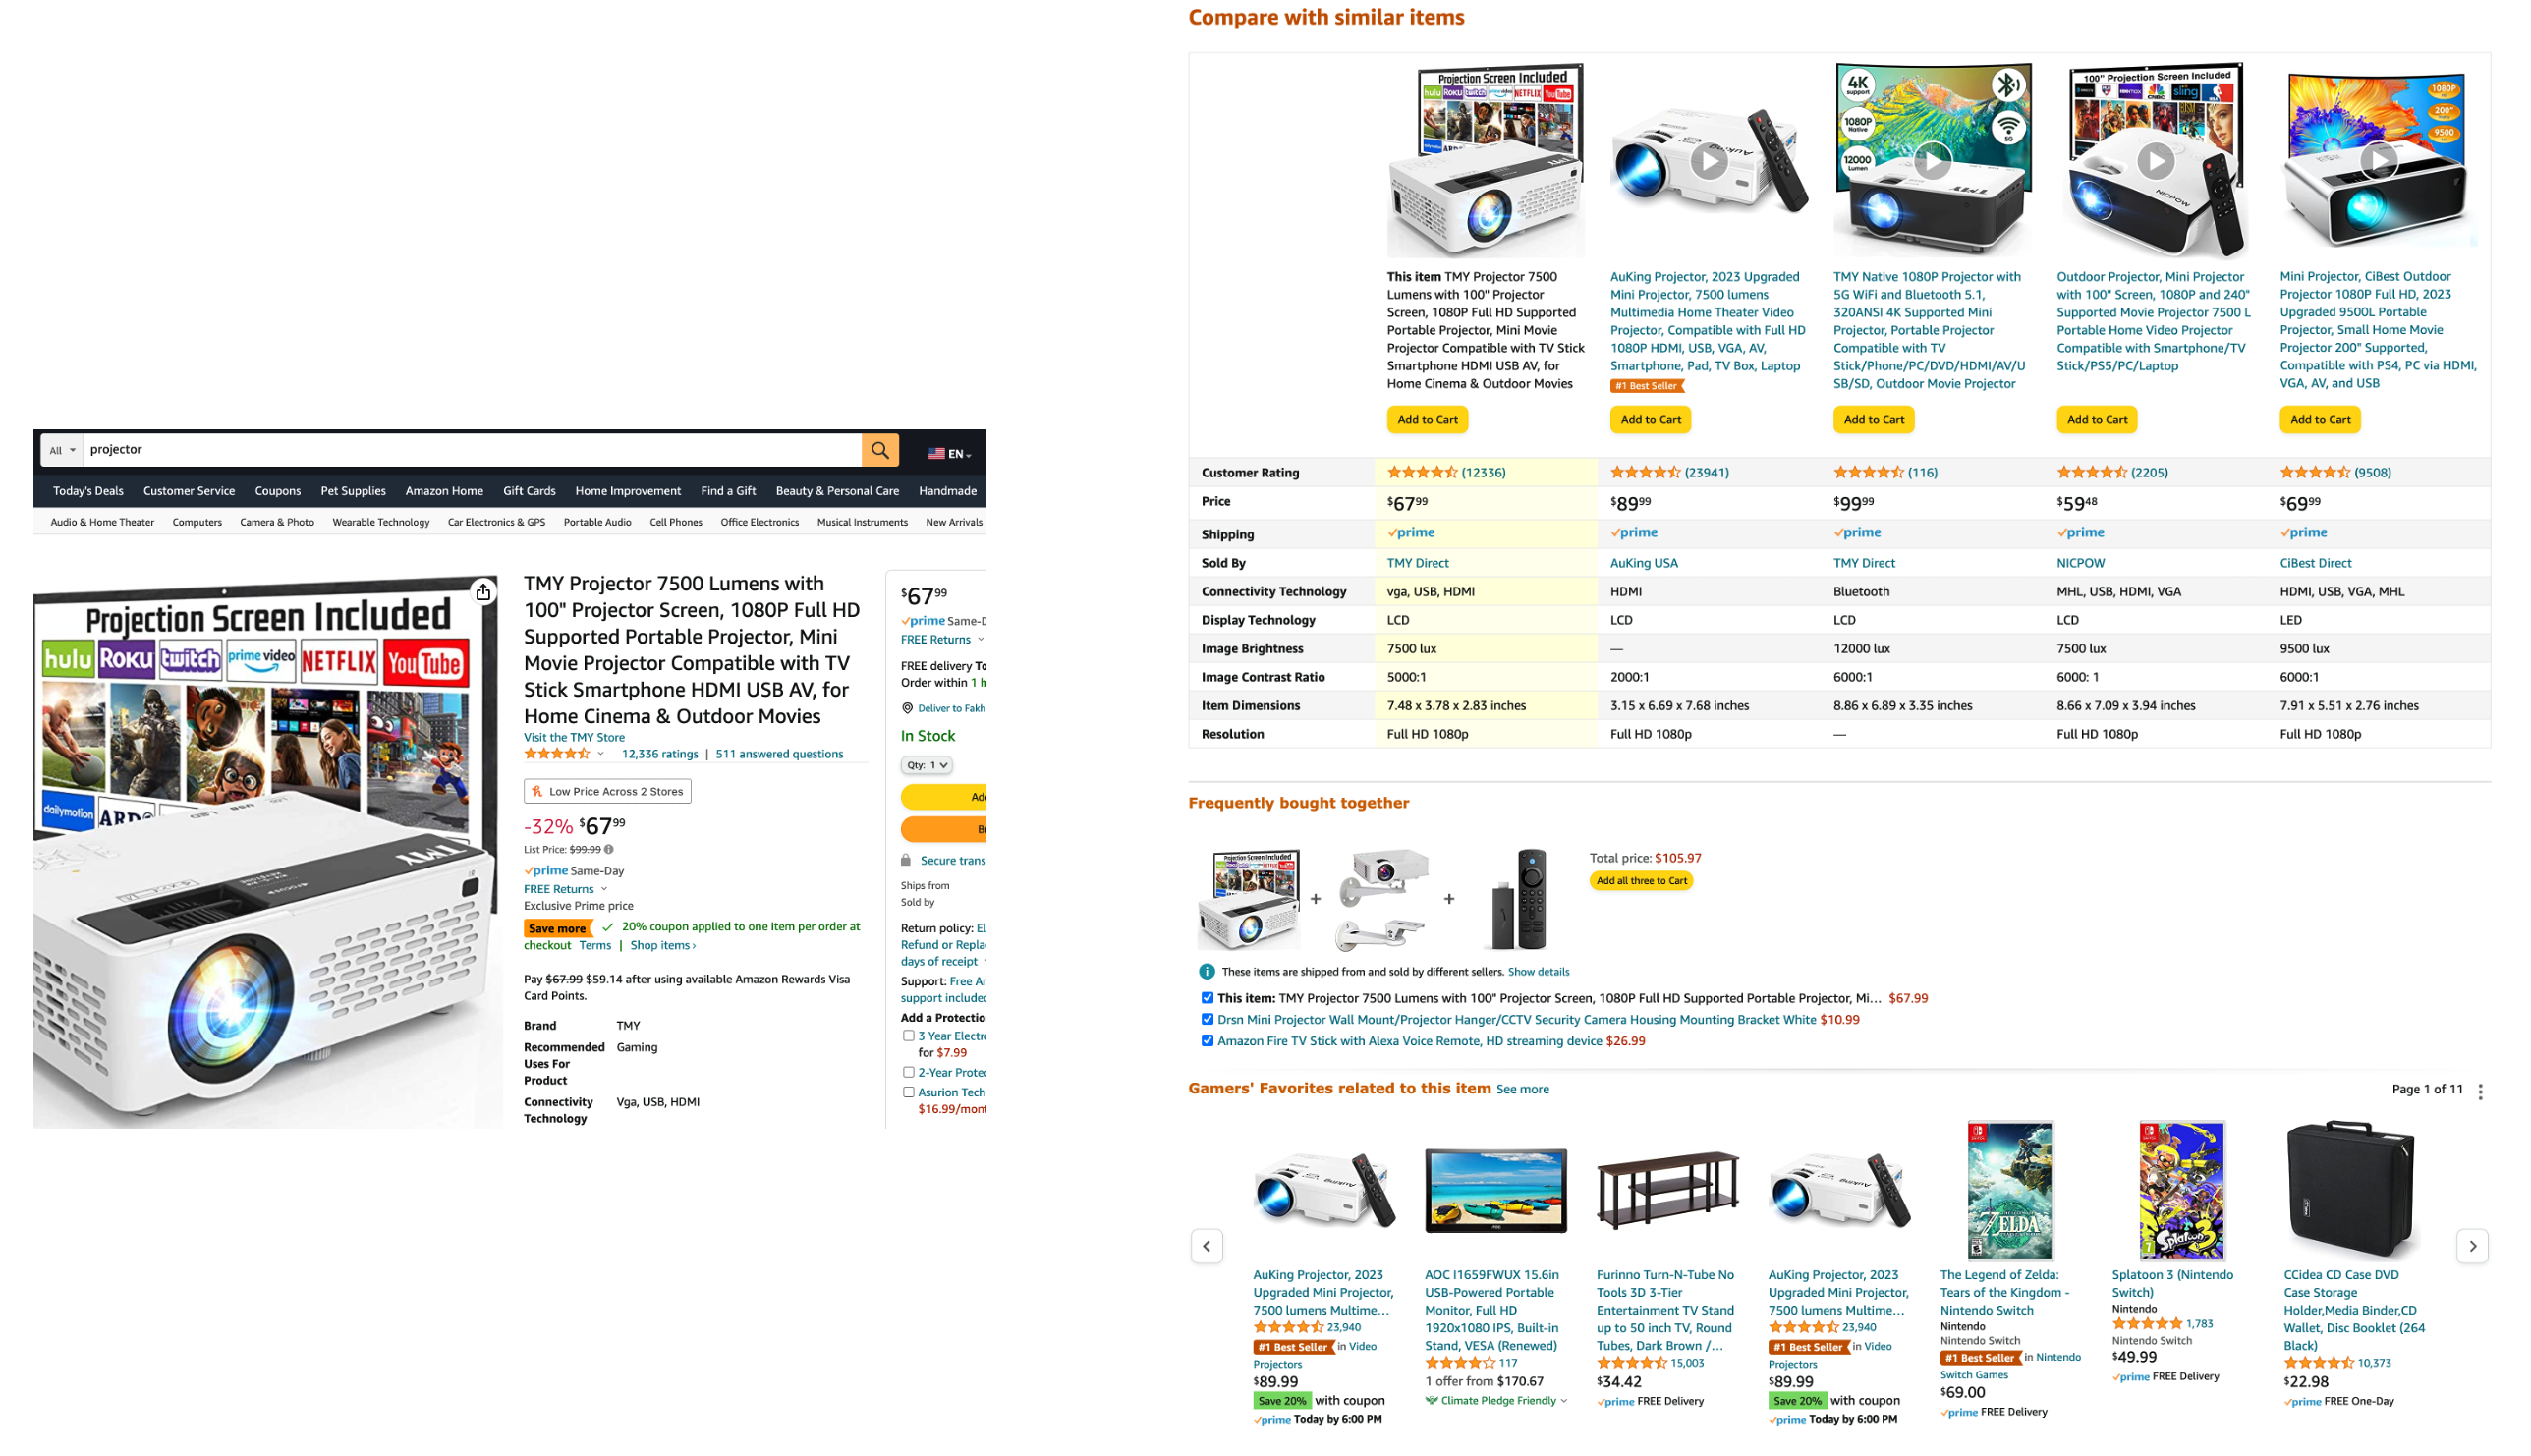

WHITEBOARD >>

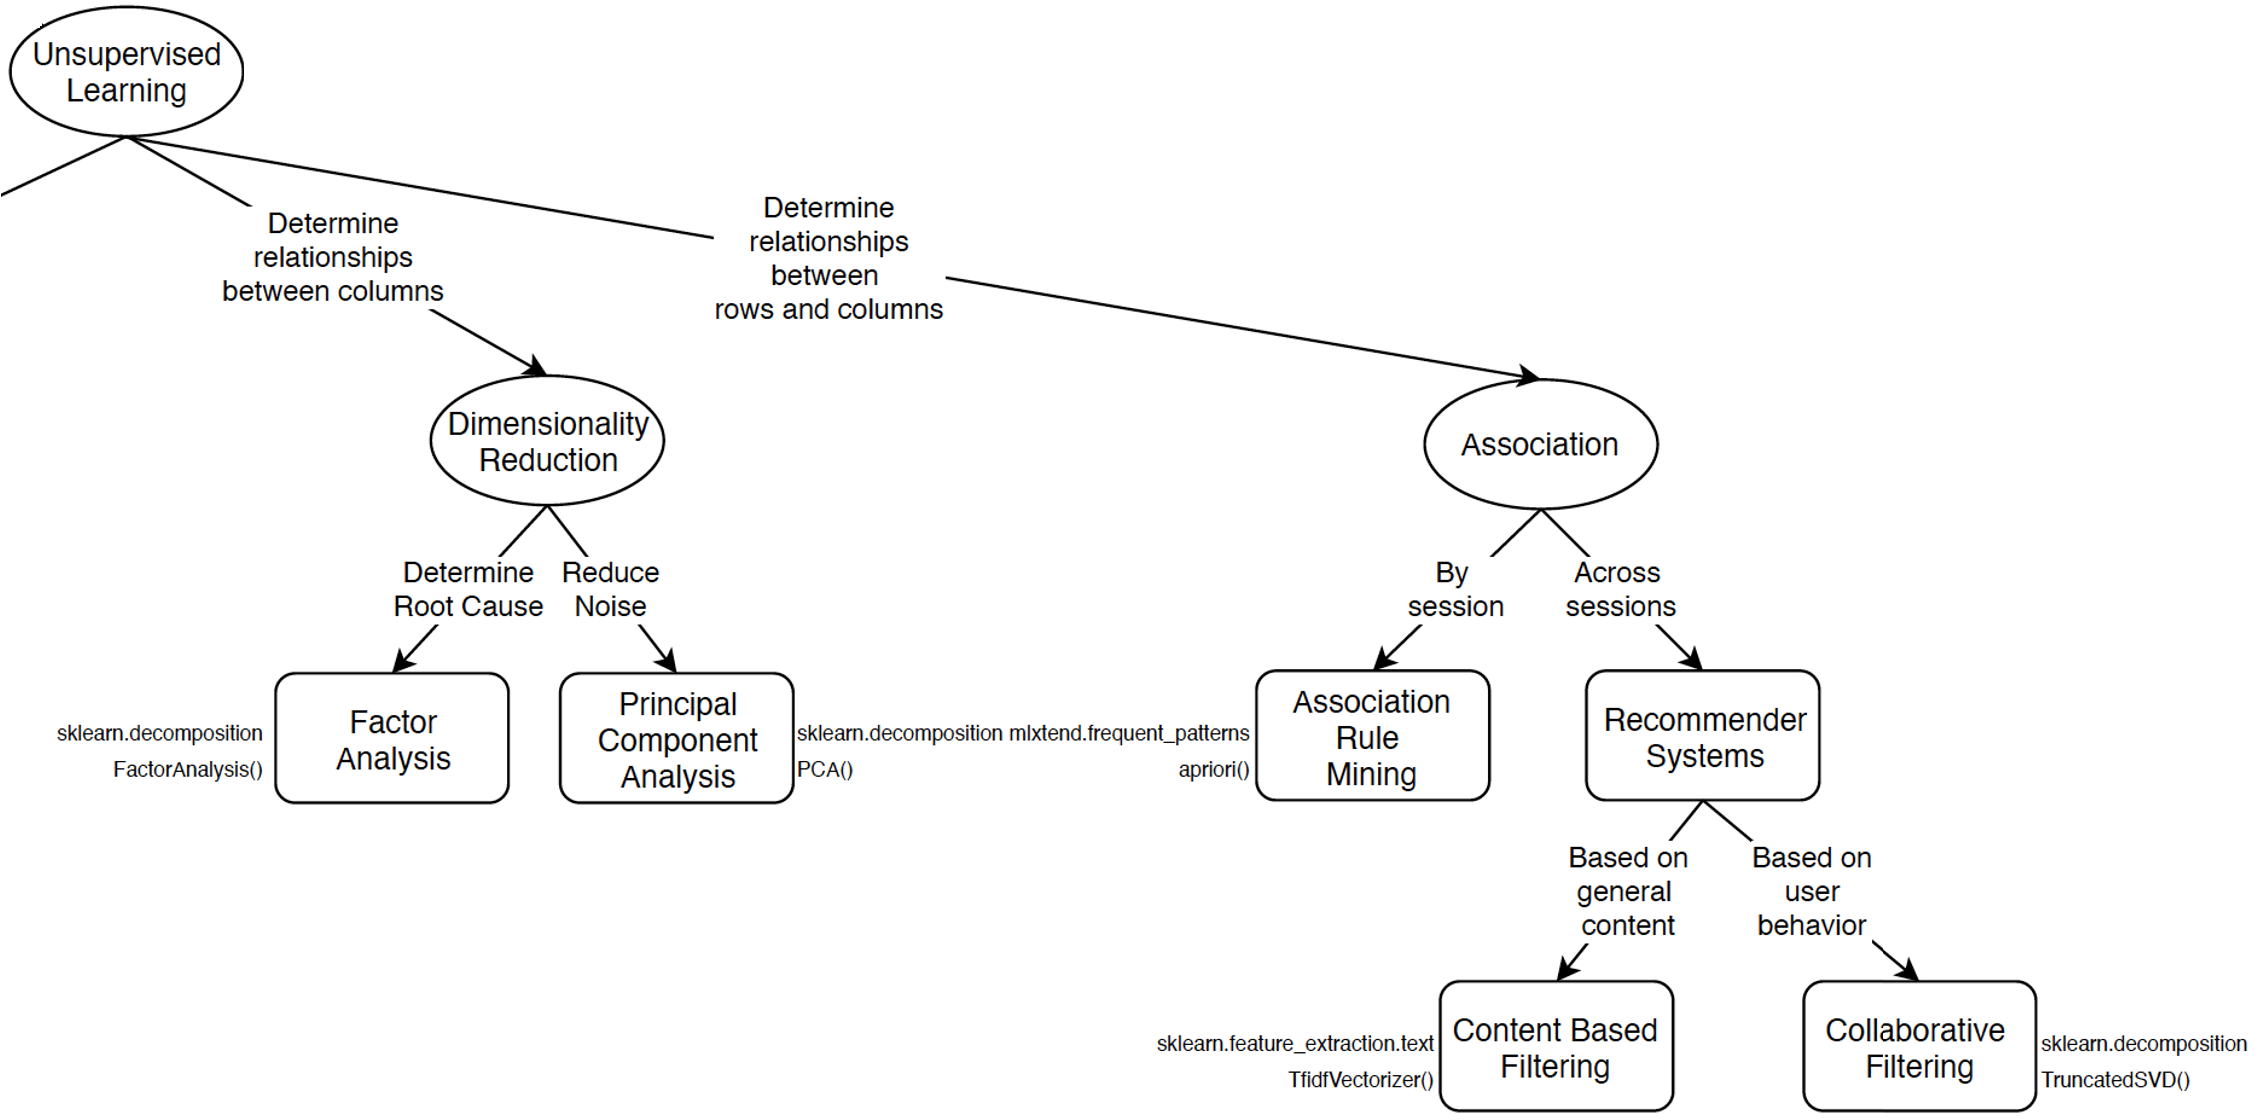

<< WHITEBOARD

utexas_ds_orie_divider_gray.png